In [1]:
from ssh_chain_sq import (PHOTONICChain, min_pairwise_gap, sweep_discriminability)
import thesis_cmaps                    # registers the "thesis_cmap" colormaps
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import scienceplots
plt.style.use(['science', 'no-latex', 'notebook'])

# chi is dimensionless (qubit frequency = 1). The swept discriminability metric
# is divided by g_const**2 (chi ~ O(g^2 kerr)); CHI_UNIT = 1e-3 (the "MHz vs
# GHz" scale) is only used for the validation printouts.
CHI_UNIT = 1e-3
CMAP     = 'thesis_cmap'


def log_heatmap(ax, x, y, Z, label='', cmap=CMAP, norm=None, contours=True):
    '''pcolormesh of Z on a LogNorm colour scale whose ticks read the actual
    value (not log10), plus optional log-spaced contour lines. Non-positive /
    non-finite entries (outside the dispersive regime) are left blank.'''
    Zp = np.where(np.isfinite(Z) & (Z > 0), Z, np.nan)
    finite = Zp[np.isfinite(Zp)]
    if finite.size == 0:
        ax.text(0.5, 0.5, 'no dispersive points', ha='center', va='center',
                transform=ax.transAxes, fontsize=8)
        return None
    if norm is None:
        vmin, vmax = finite.min(), finite.max()
        if vmin == vmax:
            vmin, vmax = vmin / 10, vmax * 10
        norm = LogNorm(vmin=vmin, vmax=vmax)
    im = ax.pcolormesh(x, y, Zp, cmap=cmap, shading='nearest', norm=norm)
    if label:
        ax.figure.colorbar(im, ax=ax, label=label)
    if contours:
        lo, hi = np.floor(np.log10(norm.vmin)), np.ceil(np.log10(norm.vmax))
        lv = np.logspace(lo, hi, int(hi - lo) + 1)
        lv = lv[(lv > norm.vmin) & (lv < norm.vmax)]
        if len(lv):
            cs = ax.contour(x, y, Zp, levels=lv, colors='w', linewidths=0.5)
            ax.clabel(cs, inline=True, fontsize=6, fmt=lambda v: f'{v:g}')
    return im

# Dispersive shift of a probe resonator by the transmon chain

`PHOTONICChain` Bogoliubov-diagonalizes the chain's quadratic part, so in the
$\eta$ basis

$$H_\mathrm{chain}=\sum_j \omega_j\,\eta^\dagger_j\eta_j
  +\sum_{ijkl}V_{ijkl}\,\eta^\dagger_i\eta^\dagger_j\eta_k\eta_l,
  \qquad \omega_j = 2\,\mathrm{diag}(H_C)_j .$$

A **new probe resonator** $\alpha$ of frequency $\omega_r^\mathrm{new}$ couples to
the sites,

$$(\alpha^\dagger-\alpha)\sum_j g_j\,(b^\dagger_j-b_j)
  \;\xrightarrow{\ \text{diag.}\ }\;
  (\alpha^\dagger-\alpha)\sum_j g'_j\,(\eta^\dagger_j-\eta_j).$$

**Pipeline** (`PHOTONICChain`):

1. `compute_resonator_mode_transformation` — Bogoliubov-diagonalize the
   $(n{+}1)$-mode quadratic part into modes $\beta_k$; pick $\beta_0$, the one
   closest in frequency to $\omega_r^\mathrm{new}$.
2. `transform_kerr_to_resonator_basis` — push $V$ into the $\beta$ basis.
3. `_resonator_number_kerr_matrix` — keep only
   $\big(\sum_{ij}V''_{ij}\,\beta^\dagger_i\beta_j\big)\beta_0^\dagger\beta_0$
   (single-excitation subspace of the chain).
4. `_diagonalize_degenerate_blocks` — diagonalize $V''$ in each degenerate block.
5. $\displaystyle \chi_i = V''_{ii}+\sum_{j\neq i}\frac{|V''_{ij}|^2}{E_i-E_j}.$

Entry points: `compute_resonator_dispersive_shift_vec` (standing wave),
`compute_resonator_dispersive_shift_vec_from_sites` (arbitrary $g_j$).
Helpers used below: `probe_freq_in_gap`, `mode_discriminability`,
`sweep_discriminability`.

In [2]:
N        = 3
Omega_J  = 1.0
Chi_J    = 0.0
kerr     = 0.05
gamma    = 0.0
omega_r  = 1.0            # original cavity -- decoupled here (gamma = 0)
g_const  = 1.0e-3        # uniform per-site probe coupling -- small, so nearly every
                         # (Omega_C, Chi_C) point stays dispersive and the g^2-
                         # normalized metric sits at its g -> 0 limit
NORM     = g_const ** 2  # chi ~ O(g^2 kerr): divide by this for a g-independent metric

def make_chain(Omega_C, Chi_C, pbc=False):
    return PHOTONICChain(N=N, Omega_C=Omega_C, Chi_C=Chi_C, omega_r=omega_r,
                         gamma=gamma, fock_photon=1, Omega_J=Omega_J,
                         Chi_J=Chi_J, kerr=kerr, PBC=pbc)

chain   = make_chain(0.6, 0.35)
n       = chain.n
g_sites = np.full(n, g_const)
print('eta-mode frequencies:', np.round(2.0 * np.diag(chain.H_C)[:n].real, 4))

eta-mode frequencies: [0.6638 0.7522 0.8448 1.1288 1.1927 1.2436]


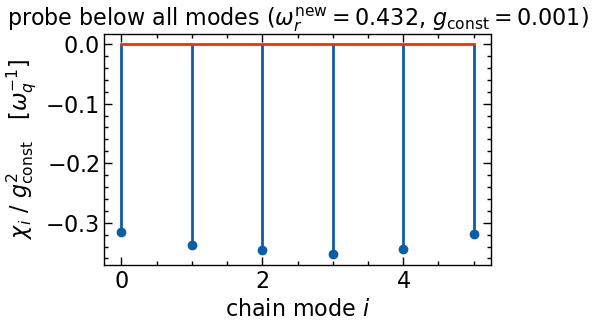

g' (probe -> eta)  : [ 0.     -0.2076  0.     -0.4945  0.      2.137 ]  (in units of g_const)
chi / g_const^2     : [-0.3163 -0.3373 -0.3461 -0.3527 -0.344  -0.3196]  [1/w_q]
min|d chi| / g^2    : 0.002169431565085828  [1/w_q]


In [3]:
omega_r_new = chain.probe_freq_in_gap(-1)          # -1 -> below every mode
gp  = chain.compute_coupling_vec_from_sites(g_sites)
chi = chain.compute_resonator_dispersive_shift_vec_from_sites(
    omega_r_new, g_sites, degeneracy_tol=1e-6, dispersive_tol=0.3)

fig, ax = plt.subplots(figsize=(5, 3))
ax.stem(np.arange(n), chi / NORM)
ax.set_xlabel('chain mode $i$')
ax.set_ylabel(r'$\chi_i\ /\ g_{\rm const}^2\quad[\omega_q^{-1}]$')
ax.set_title(rf'probe below all modes ($\omega_r^{{\rm new}}={omega_r_new:.3f}$, '
             rf'$g_{{\rm const}}={g_const:g}$)')
plt.show()

print("g' (probe -> eta)  :", np.round(gp / g_const, 4), " (in units of g_const)")
print("chi / g_const^2     :", np.round(chi / NORM, 4), " [1/w_q]")
print("min|d chi| / g^2    :", chain.mode_discriminability(
      omega_r_new, g_sites, normalize=NORM, dispersive_tol=0.3), " [1/w_q]")

## Validation against a brute-force diagonalization

Small chain ($N=2$): build $H$ explicitly in the $\eta$ basis (full Kerr, full
coupling), diagonalize with QuTiP, and read

$$\chi_i^\mathrm{bf}=\big[E(1_i,1_\mathrm{ph})-E(1_i,0_\mathrm{ph})\big]
                   -\big[E(0,1_\mathrm{ph})-E(0,0_\mathrm{ph})\big].$$

The method keeps only the $\beta_0^\dagger\beta_0$-weighted single-excitation
piece, so the residual is $\mathcal{O}(\mathrm{kerr}^2)$ — order $10\%$ at
`kerr` $=0.02$, shrinking $\propto\mathrm{kerr}$ as it drops.

In [4]:
import qutip as qt

def brute_force_chi(chn, wr, g_prime, Ntr=4, Nr=8):
    # Hilbert dim = Ntr**(2N) * Nr; for N=2 that is 4**4 * 8 = 2048 -> a ~67 MB
    # dense H. Do NOT raise Ntr/Nr on g15 (14 GB): (Ntr,Nr)=(6,12) is dim 15552,
    # ~4 GB per matrix, and the eigensolver needs several -> OOM.
    m    = chn.n
    pref = 1.0 if chn.statistics == 'fermion' else 2.0
    oe   = pref * np.diag(chn.H_C)[:m].real
    gpv  = np.asarray(g_prime, dtype=float)
    Vk   = chn.kerr_operator.tensor
    dims = [Ntr] * m + [Nr]
    emb  = lambda o, k: [o if p == k else qt.qeye(d) for p, d in enumerate(dims)]
    b    = [qt.tensor(*emb(qt.destroy(Ntr), i)) for i in range(m)]
    a    = qt.tensor(*emb(qt.destroy(Nr), m))
    H = sum(oe[i] * b[i].dag() * b[i] for i in range(m)) + wr * a.dag() * a
    for i, j, k, l in np.argwhere(np.abs(Vk) > 1e-14):
        H += Vk[i, j, k, l] * b[i].dag() * b[j].dag() * b[k] * b[l]
    H += (a.dag() - a) * sum(gpv[j] * (b[j].dag() - b[j]) for j in range(m))
    ev, es = H.eigenstates()
    def E(ph, exc=None):
        ket = [qt.basis(Ntr, 0) for _ in range(m)] + [qt.basis(Nr, ph)]
        if exc is not None:
            ket[exc] = qt.basis(Ntr, 1)
        ref = qt.tensor(*ket)
        return ev[int(np.argmax([abs(x.overlap(ref)) ** 2 for x in es]))]
    e00, e01 = E(0), E(1)
    return np.array([(E(1, i) - E(0, i)) - (e01 - e00) for i in range(m)])


# gentler parameters just for the cross-check: a bigger kerr / coupling only
# make the O(kerr^2) residual and the QuTiP eigenstate identification noisier.
kerr_val, g_val = 0.02, 5e-3
cbf   = PHOTONICChain(N=2, Omega_C=0.6, Chi_C=0.35, omega_r=omega_r, gamma=gamma,
                      fock_photon=1, Omega_J=Omega_J, Chi_J=Chi_J, kerr=kerr_val, PBC=False)
m     = cbf.n
wr_bf = cbf.probe_freq_in_gap(-1)                       # below all modes

for tag, gs in {'uniform ': np.full(m, g_val),
                'gradient': g_val * (1.0 + 0.5 * np.arange(m))}.items():
    gpr = cbf.compute_coupling_vec_from_sites(gs)
    cm  = cbf.compute_resonator_dispersive_shift_from_gprime(wr_bf, gpr, dispersive_tol=1.0)
    cb  = brute_force_chi(cbf, wr_bf, gpr)
    print(f"{tag}:  method  {np.round(cm/CHI_UNIT,4)}")
    print(f"{'':9s}  brute   {np.round(cb/CHI_UNIT,4)}")
    print(f"{'':9s}  rel err {np.round(np.abs(cm-cb)/np.abs(cb),3)}\n")

uniform :  method  [-0.0036 -0.0041 -0.0042 -0.0037]
           brute   [-0.0038 -0.0044 -0.0039 -0.0033]
           rel err [0.049 0.063 0.076 0.103]

gradient:  method  [-0.0144 -0.0171 -0.0172 -0.0143]
           brute   [-0.0153 -0.0185 -0.0197 -0.0137]
           rel err [0.056 0.073 0.127 0.042]



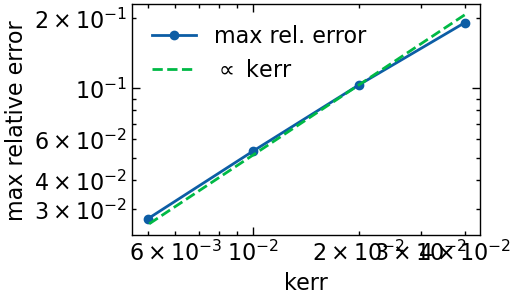

{0.04: 0.1906, 0.02: 0.103, 0.01: 0.0535, 0.005: 0.0273}


In [5]:
# residual vs Kerr strength: the single-excitation-subspace truncation is O(kerr^2)
kerr_scan, rel_err = np.array([0.04, 0.02, 0.01, 5e-3]), []
for kk in kerr_scan:
    ck  = PHOTONICChain(N=2, Omega_C=0.6, Chi_C=0.35, omega_r=omega_r, gamma=gamma,
                        fock_photon=1, Omega_J=Omega_J, Chi_J=Chi_J, kerr=kk, PBC=False)
    wr  = ck.probe_freq_in_gap(-1)
    gpr = ck.compute_coupling_vec_from_sites(np.full(ck.n, g_val))
    cm  = ck.compute_resonator_dispersive_shift_from_gprime(wr, gpr, dispersive_tol=1.0)
    cb  = brute_force_chi(ck, wr, gpr)
    rel_err.append(np.max(np.abs(cm - cb) / np.abs(cb)))
rel_err = np.array(rel_err)

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.loglog(kerr_scan, rel_err, 'o-', label='max rel. error')
ax.loglog(kerr_scan, rel_err[1] * kerr_scan / kerr_scan[1], '--', label=r'$\propto$ kerr')
ax.set_xlabel('kerr'); ax.set_ylabel('max relative error'); ax.legend()
plt.show()
print(dict(zip(kerr_scan.tolist(), np.round(rel_err, 4).tolist())))

## Mode discriminability

For a chosen probe frequency and coupling profile, each chain mode picks up a
dispersive shift $\chi_i$. Reading off *which* mode is excited from a single
dispersive measurement is limited by the **closest pair**,
$\min_{i<j}|\chi_i-\chi_j|=\min\!\big(\mathrm{diff}(\mathrm{sort}\,\chi)\big)$
(`min_pairwise_gap`). Since $\chi\sim\mathcal{O}(g^2\,\mathrm{kerr})$ we divide by
$g_\mathrm{const}^2$ (`NORM`) for a coupling-independent figure of merit.

The SSH gap closes at $\chi_C=0$; with the probe sitting between the chain levels
the dispersive regime is lost there, so every sweep is done separately for
$\chi_C<0$ and $\chi_C>0$. Colour scales are logarithmic with real-value ticks.

In [6]:
GRID           = 40
omega_C_values = np.linspace(0.1, 0.8, GRID)
chi_C_neg      = np.linspace(-0.8, -0.1, GRID)
chi_C_pos      = np.linspace( 0.1,  0.8, GRID)

def run_bands(gap_index, pbc=False, label='', g=g_const):
    '''min|d chi| / g^2 over the (Omega_C, Chi_C) grid for chi_C<0 and chi_C>0,
    probe adaptively placed in gap `gap_index` at every grid point.'''
    kw = dict(g_sites=np.full(n, g), gap_index=gap_index, normalize=g ** 2,
              dispersive_tol=0.3, degeneracy_tol=1e-6)
    mk = lambda oc, cc: make_chain(oc, cc, pbc)
    return dict(label=label, gap_index=gap_index, g=g,
                neg=sweep_discriminability(mk, omega_C_values, chi_C_neg, **kw),
                pos=sweep_discriminability(mk, omega_C_values, chi_C_pos, **kw))

def report_best(res):
    for sgn, cv in [('neg', chi_C_neg), ('pos', chi_C_pos)]:
        G = res[sgn]['gap_grid']
        if not np.isfinite(G).any():
            print(f"  {sgn}: no dispersive points"); continue
        b   = np.unravel_index(np.nanargmax(G), G.shape)
        chi = res[sgn]['chi_cube'][b]
        wr  = res[sgn]['omega_r_new_grid'][b]
        print(f"  {sgn}: best min|d chi|/g^2 = {G[b]:.3g} [1/w_q] at Omega_C="
              f"{omega_C_values[b[1]]:.3f}, Chi_C={cv[b[0]]:.3f} "
              f"(omega_r_new={wr:.3f})")
        print(f"        chi/g^2 = {np.round(chi / res['g'] ** 2, 4)}")
    return res

  neg: best min|d chi|/g^2 = 0.00678 [1/w_q] at Omega_C=0.118, Chi_C=-0.100 (omega_r_new=0.903)
        chi/g^2 = [ -8.2917  -9.2255 -12.4519 -12.4587  -9.2471  -8.3131]
  pos: best min|d chi|/g^2 = 0.0178 [1/w_q] at Omega_C=0.100, Chi_C=0.800 (omega_r_new=0.911)
        chi/g^2 = [-10.304  -10.5477 -10.4108 -10.4285 -10.5673 -10.3222]


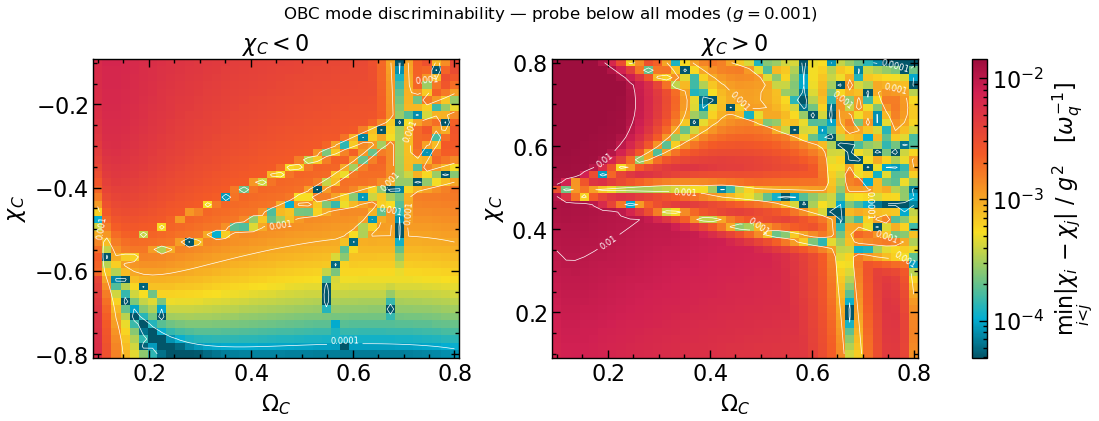

In [7]:
# probe below all modes (gap_index = -1): the two sign regions, side by side
below = report_best(run_bands(-1, pbc=False, label='below all'))

gn = below['neg']['gap_grid']; gp = below['pos']['gap_grid']
allv = np.concatenate([gn[np.isfinite(gn)], gp[np.isfinite(gp)]]); allv = allv[allv > 0]
norm = LogNorm(*np.percentile(allv, [2, 98]))          # robust to near-resonant outliers

METRIC_LABEL = r'$\min_{i<j}|\chi_i-\chi_j|\ /\ g^2\quad[\omega_q^{-1}]$'

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
last = None
for ax, cv, G, ttl in [(axes[0], chi_C_neg, gn, r'$\chi_C<0$'),
                       (axes[1], chi_C_pos, gp, r'$\chi_C>0$')]:
    im = log_heatmap(ax, omega_C_values, cv, G, norm=norm)
    last = im or last
    ax.set_xlabel(r'$\Omega_C$'); ax.set_ylabel(r'$\chi_C$'); ax.set_title(ttl)
fig.colorbar(last, ax=list(axes), label=METRIC_LABEL)
fig.suptitle(rf'OBC mode discriminability — probe below all modes ($g={g_const:g}$)')
plt.show()

### Smallest shift magnitude

`mode_discriminability` asks *can I tell two excited modes apart*
($\min_{i<j}|\chi_i-\chi_j|$). The complementary question is *does every mode
leave a visible imprint at all* — $\min_i|\chi_i|$, the weakest per-mode shift;
if it falls below the probe linewidth that mode is invisible. The new
`PHOTONICChain.min_abs_shift` returns it (normalized by $g^2$, units
$[\omega_q^{-1}]$); on a grid it comes straight out of the `chi_cube` that
`sweep_discriminability` already stores — no extra sweep. Below, from the same
"probe below all modes" scan.

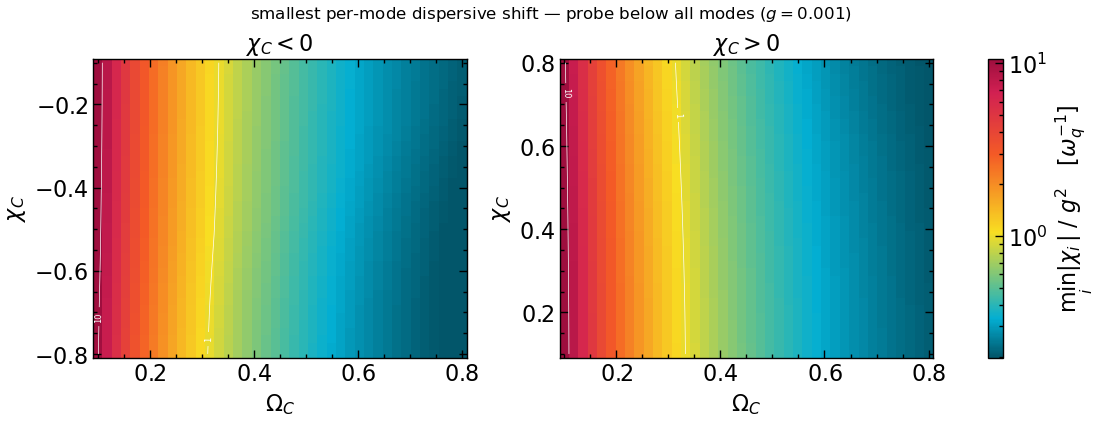

min_abs_shift (method): 0.3163137701330561


In [8]:
# smallest per-mode dispersive shift, min_i |chi_i| / g^2, from the "below all"
# scan (chi_cube already holds chi at every grid point; all-NaN slice -> NaN)
ma_n = np.min(np.abs(below['neg']['chi_cube']), axis=-1) / g_const ** 2
ma_p = np.min(np.abs(below['pos']['chi_cube']), axis=-1) / g_const ** 2

MINABS_LABEL = r'$\min_i |\chi_i|\ /\ g^2\quad[\omega_q^{-1}]$'
allv = np.concatenate([ma_n[np.isfinite(ma_n) & (ma_n > 0)],
                       ma_p[np.isfinite(ma_p) & (ma_p > 0)]])
norm = LogNorm(*np.percentile(allv, [2, 98]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
last = None
for ax, cv, G, ttl in [(axes[0], chi_C_neg, ma_n, r'$\chi_C<0$'),
                       (axes[1], chi_C_pos, ma_p, r'$\chi_C>0$')]:
    im = log_heatmap(ax, omega_C_values, cv, G, norm=norm)
    last = im or last
    ax.set_xlabel(r'$\Omega_C$'); ax.set_ylabel(r'$\chi_C$'); ax.set_title(ttl)
fig.colorbar(last, ax=list(axes), label=MINABS_LABEL)
fig.suptitle(rf'smallest per-mode dispersive shift — probe below all modes ($g={g_const:g}$)')
plt.show()

# single-point sanity: the class method matches the cube derivation
_wr = chain.probe_freq_in_gap(-1)
print('min_abs_shift (method):', chain.min_abs_shift(_wr, g_sites, normalize=NORM, dispersive_tol=0.3))

### How does this depend on $g$?

In the dispersive limit the whole pipeline is a power series in $g'/\Delta$:

$$\chi_i(g)=c_i^{(2)}\,g^2+c_i^{(4)}\,g^4+\dots
  \;\Rightarrow\;
  \chi_i-\chi_j=\big(c_i^{(2)}-c_j^{(2)}\big)g^2+\big(c_i^{(4)}-c_j^{(4)}\big)g^4+\dots$$

So $\chi_i$ **and** $\min_{i<j}|\chi_i-\chi_j|$ are exactly $\mathcal{O}(g^2)$ as
$g\to0$ (log–log slope $2$, left panel below), and $\min|\Delta\chi|/g^2$
converges to a $g$-independent number with units $[\omega_q^{-1}]$ — essentially
$1/\Delta_{\rm eff}$, since $\chi\approx g^2/\Delta$.

The plots *do* shift when $g$ is not small, for two reasons:

1. the dispersive cut $|g'_j|/|\omega_j-\omega_r|<$ `dispersive_tol` scales with
   $g$, so the blank (non-dispersive) patches **shrink as $g$ drops**;
2. the $g^4$ and higher terms are $10$–$30\%$ corrections at $g=10^{-2}$ and they
   shift each $\chi_i$ by a *different* amount, so the **closest pair can
   reshuffle** — $\min|\Delta\chi|$ then has kinks and $\min|\Delta\chi|/g^2$
   swings around (up to $\sim5\times$) until $g\lesssim10^{-3}$.

That is why `g_const` $=10^{-3}$: at the $g\to0$ limit everywhere, still far above
double-precision noise. It does **not** "just grow" $\propto g^2$ once normalized —
the normalization only becomes exact in the limit.

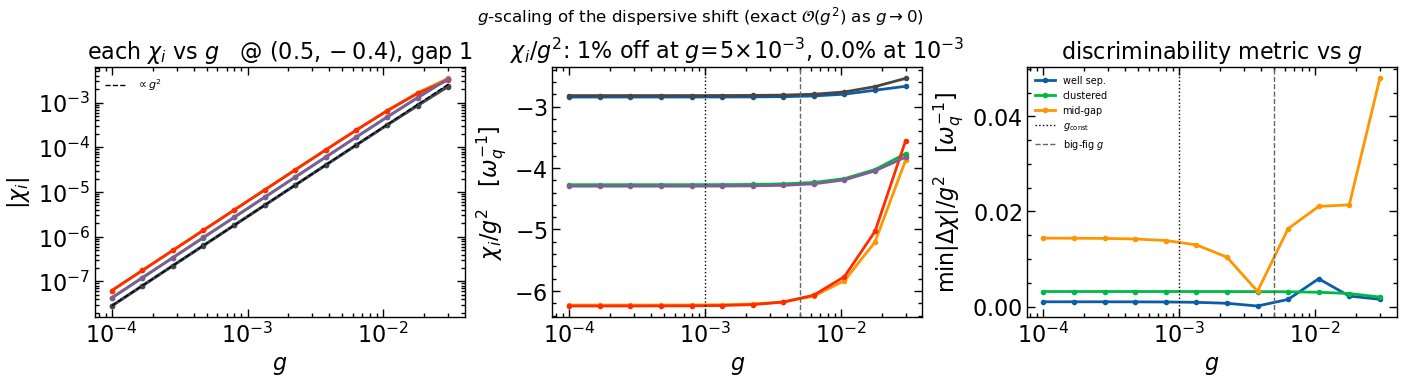

In [9]:
# --- does the dispersive shift really go as g^2, and to what extent? ---
gs_scan = np.geomspace(3e-2, 1e-4, 12)

(oc0, cc0), gi0 = (0.5, -0.4), 1                         # one representative point
ch0 = make_chain(oc0, cc0); wr0 = ch0.probe_freq_in_gap(gi0)
chi_g = np.array([ch0.compute_resonator_dispersive_shift_from_gprime(
                      wr0, ch0.compute_coupling_vec_from_sites(np.full(n, g)), dispersive_tol=9.0)
                  for g in gs_scan])                      # shape (n_g, n_modes)
plateau = chi_g[-1] / gs_scan[-1] ** 2                    # the g -> 0 limit of chi_i / g^2
k5, k1 = np.argmin(np.abs(gs_scan - 5e-3)), np.argmin(np.abs(gs_scan - 1e-3))

fig, (a0, a1, a2) = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)

for i in range(n):
    a0.loglog(gs_scan, np.abs(chi_g[:, i]), 'o-', ms=3)
a0.loglog(gs_scan, np.abs(chi_g[-1, 0]) * (gs_scan / gs_scan[-1]) ** 2, 'k--', lw=1, label=r'$\propto g^2$')
a0.set_xlabel('$g$'); a0.set_ylabel(r'$|\chi_i|$'); a0.legend(fontsize=8)
a0.set_title(rf'each $\chi_i$ vs $g$   @ $({oc0},{cc0})$, gap {gi0}')

for i in range(n):
    a1.semilogx(gs_scan, chi_g[:, i] / gs_scan ** 2, 'o-', ms=3)
for gv, c in [(5e-3, '0.4'), (1e-3, 'k')]:
    a1.axvline(gv, ls=':' if gv == 1e-3 else '--', c=c, lw=1)
dev5 = np.abs(chi_g[k5] / gs_scan[k5] ** 2 / plateau - 1).max()
dev1 = np.abs(chi_g[k1] / gs_scan[k1] ** 2 / plateau - 1).max()
a1.set_xlabel('$g$'); a1.set_ylabel(r'$\chi_i/g^2\quad[\omega_q^{-1}]$')
a1.set_title(rf'$\chi_i/g^2$: {100*dev5:.0f}% off at $g\!=\!5\!\times\!10^{{-3}}$,'
             rf' {100*dev1:.1f}% at $10^{{-3}}$')

for (oc, cc), gi, lbl in [((0.3, -0.6), -1, 'well sep.'),
                          ((0.6, -0.15), -1, 'clustered'),
                          ((0.5, -0.4), 1, 'mid-gap')]:
    ch = make_chain(oc, cc); wr = ch.probe_freq_in_gap(gi)
    mg = np.array([min_pairwise_gap(ch.compute_resonator_dispersive_shift_from_gprime(
              wr, ch.compute_coupling_vec_from_sites(np.full(n, g)), dispersive_tol=9.0))
          for g in gs_scan])
    a2.semilogx(gs_scan, mg / gs_scan ** 2, 'o-', ms=3, label=lbl)
a2.axvline(1e-3, ls=':', c='k', lw=1, label=r'$g_{\rm const}$')
a2.axvline(5e-3, ls='--', c='0.4', lw=1, label='big-fig $g$')
a2.set_xlabel('$g$'); a2.set_ylabel(r'$\min|\Delta\chi|/g^2\quad[\omega_q^{-1}]$')
a2.legend(fontsize=7); a2.set_title('discriminability metric vs $g$')

fig.suptitle(r'$g$-scaling of the dispersive shift (exact $\mathcal{O}(g^2)$ as $g\to0$)')
plt.show()

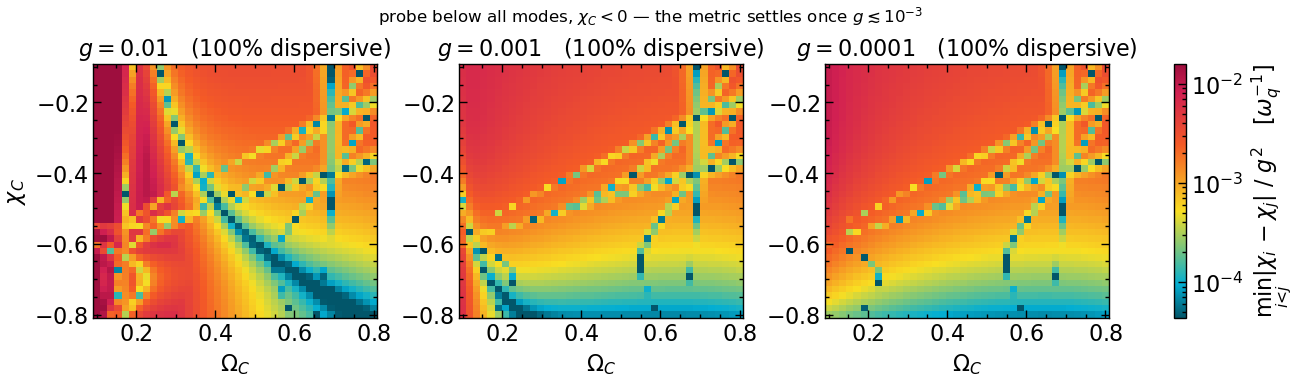

In [10]:
# the same "below all" heat map (chi_C < 0) at three coupling strengths:
# g = 1e-3 and 1e-4 are identical (converged); g = 1e-2 still shows g^4 distortion.
g_try = [1e-2, 1e-3, 1e-4]
grids = [sweep_discriminability(make_chain, omega_C_values, chi_C_neg, np.full(n, g),
                                gap_index=-1, normalize=g ** 2, dispersive_tol=0.3)['gap_grid']
         for g in g_try]

allv = np.concatenate([G[np.isfinite(G) & (G > 0)] for G in grids])
norm = LogNorm(*np.percentile(allv, [2, 98]))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
last = None
for ax, G, g in zip(axes, grids, g_try):
    im = log_heatmap(ax, omega_C_values, chi_C_neg, G, norm=norm, contours=False)
    last = im or last
    ax.set_title(rf'$g = {g:g}$   ({100*np.isfinite(G).mean():.0f}% dispersive)')
    ax.set_xlabel(r'$\Omega_C$')
axes[0].set_ylabel(r'$\chi_C$')
fig.colorbar(last, ax=list(axes), label=METRIC_LABEL)
fig.suptitle(r'probe below all modes, $\chi_C<0$ — the metric settles once $g\lesssim10^{-3}$')
plt.show()

## Probe position scan

Now sweep the probe across the chain spectrum: **below all modes**, in each
**gap between consecutive modes** $k,k{+}1$, and **above all modes**. For every
$(\Omega_C,\chi_C)$ point the probe is re-placed at the requested position
(`probe_freq_in_gap`), so "gap $k$" stays meaningful as the spectrum moves.
Rows = probe position, columns = $\chi_C$ sign, third column = the level diagram
(chain modes as **red** Lorentzians, probe as a **blue** one) at one
representative $(\Omega_C,\chi_C)$; one shared colour scale. Run at $g=5\times10^{-3}$.

**Below all $\neq$ above all.** The uniform $g_j$ is a $k=0$ (all-sites-in-phase)
drive, which in this SSH convention projects almost entirely onto the **top**
$\eta$ mode ($|g'_{\rm top}|$ is $\sim4\times$ any other). So "below all" is a
full bandwidth detuned from the mode the probe actually couples to, while "above
all" is much closer to it, and its $\chi$ is correspondingly smaller. The
below/above rows would only match for a coupling spread evenly over the spectrum.
`probe_freq_in_gap` places the edge positions `margin`$\times$bandwidth out (not a
fixed number of level spacings). The blank patches are genuinely non-dispersive:
in the diagram you can see the probe (blue) sitting *on top of* two nearly
overlapping chain modes for **gap 2–3** (the SSH gap, which closes as
$\chi_C\to0$) and **gap 4–5** (the narrow top gap).

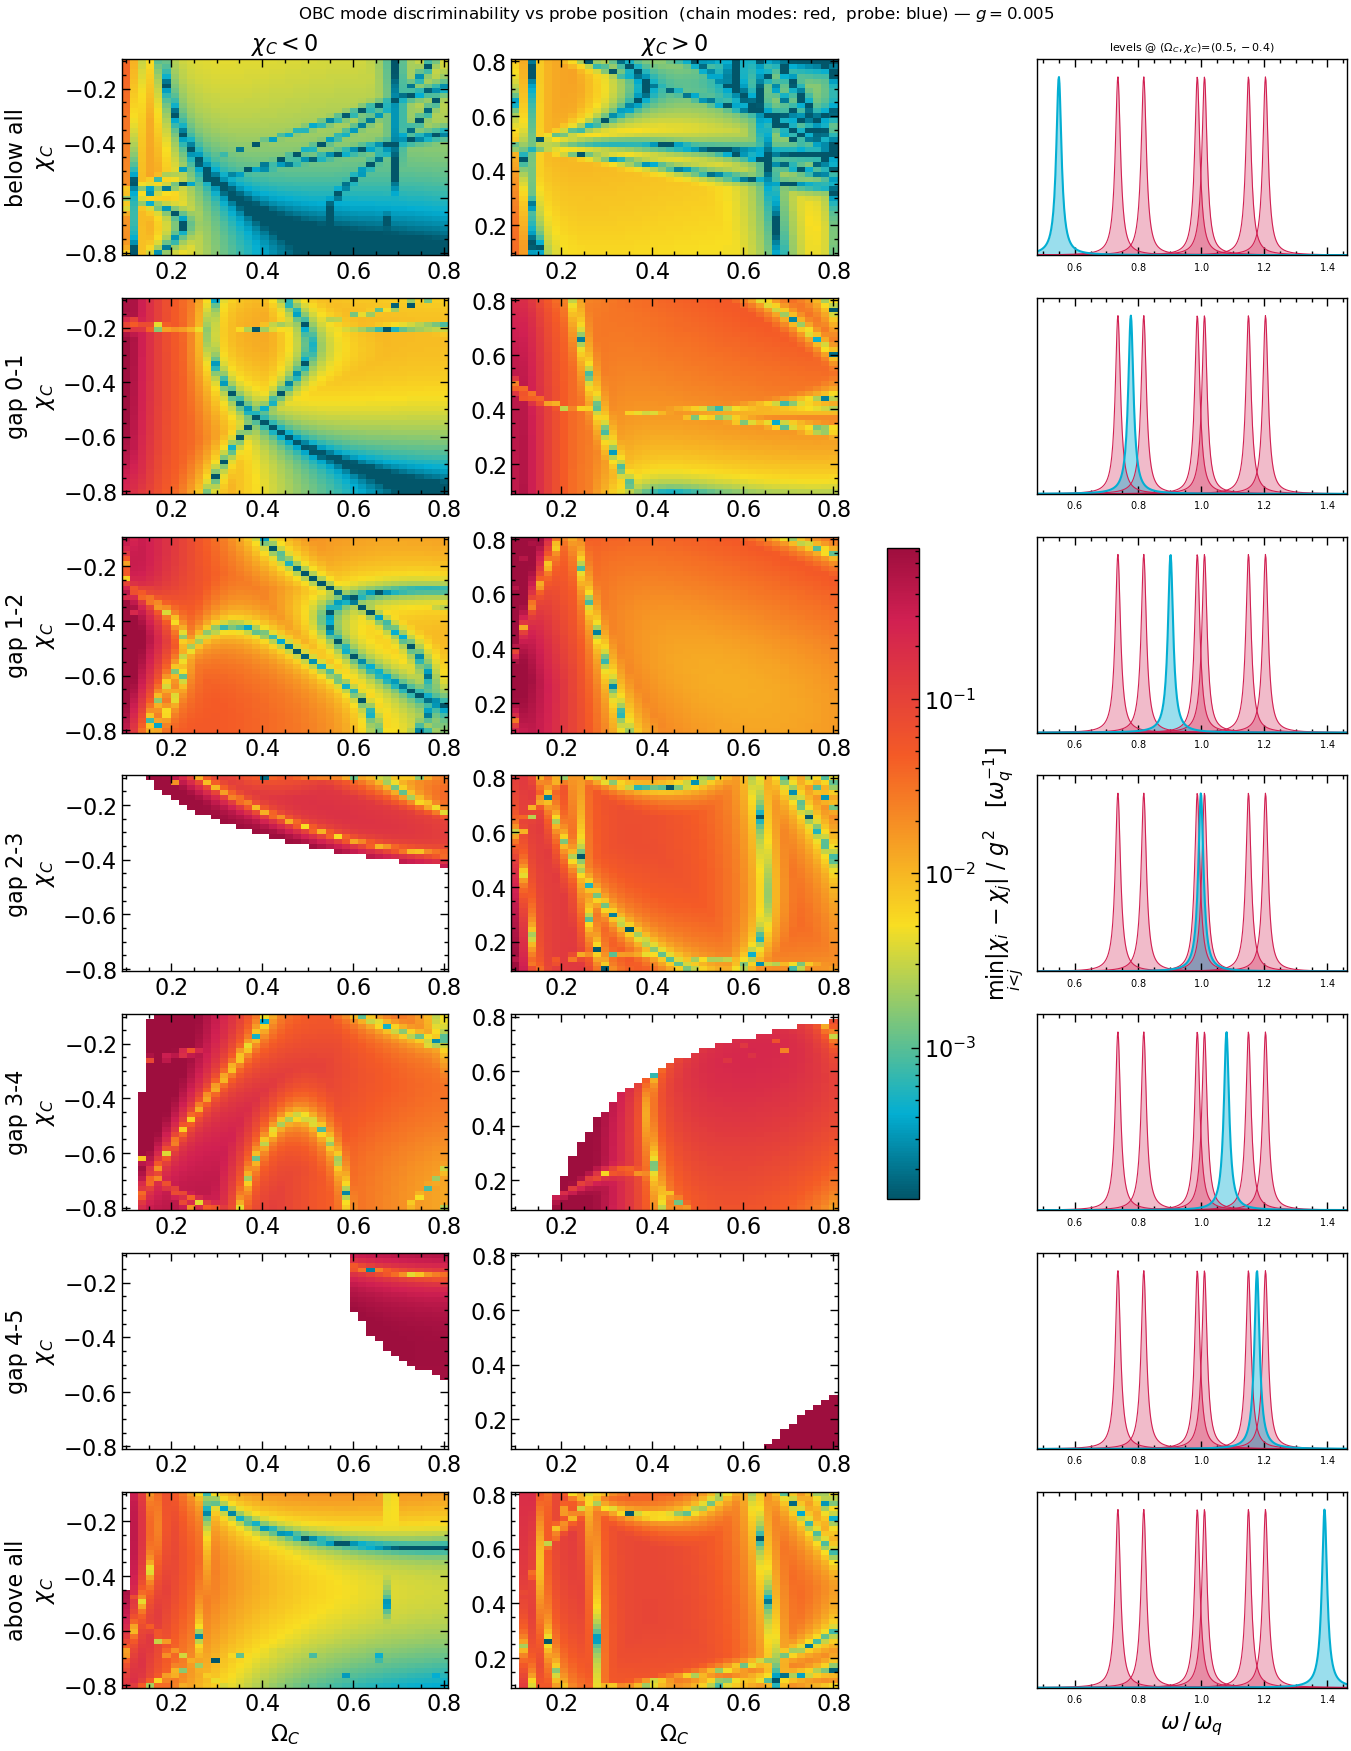

In [11]:
positions  = list(range(-1, n))                       # -1 .. n-1
pos_labels = (['below all']
              + [f'gap {k}-{k+1}' for k in range(n - 1)]
              + ['above all'])

g_big = 5e-3
scans = [run_bands(gi, pbc=False, label=lab, g=g_big)
         for gi, lab in zip(positions, pos_labels)]

allv = np.concatenate([s[sgn]['gap_grid'][np.isfinite(s[sgn]['gap_grid'])]
                       for s in scans for sgn in ('neg', 'pos')])
allv = allv[allv > 0]
norm = LogNorm(*np.percentile(allv, [2, 98]))          # robust to near-resonant outliers

# --- energy-level side diagram: chain modes (red) + probe (blue) as Lorentzians.
# The modes shift across the grid; this is drawn at one representative point.
oc_ref, cc_ref = 0.5, -0.4
ref        = make_chain(oc_ref, cc_ref)
modes_ref  = np.sort(2.0 * np.diag(ref.H_C)[:n].real)
bw         = np.ptp(modes_ref)
w_axis     = np.linspace(modes_ref.min() - 0.55 * bw, modes_ref.max() + 0.55 * bw, 600)
CHAIN_C, RES_C = '#D12052', '#03AED2'
lorentzian = lambda w0, gam=0.02: (gam / 2) ** 2 / ((w_axis - w0) ** 2 + (gam / 2) ** 2)

nr = len(positions)
fig, axes = plt.subplots(nr, 3, figsize=(13.5, 2.5 * nr), squeeze=False,
                         gridspec_kw={'width_ratios': [1, 1, 0.95]},
                         constrained_layout=True)
last = None
for r, (s, lab, gi) in enumerate(zip(scans, pos_labels, positions)):
    for c, (sgn, cv) in enumerate([('neg', chi_C_neg), ('pos', chi_C_pos)]):
        ax = axes[r, c]
        im = log_heatmap(ax, omega_C_values, cv, s[sgn]['gap_grid'], norm=norm, contours=False)
        last = im or last
        if r == 0:
            ax.set_title((r'$\chi_C<0$', r'$\chi_C>0$')[c])
        if c == 0:
            ax.set_ylabel(f'{lab}\n' + r'$\chi_C$')
        if r == nr - 1:
            ax.set_xlabel(r'$\Omega_C$')

    axd = axes[r, 2]
    for wm in modes_ref:
        axd.fill_between(w_axis, lorentzian(wm), color=CHAIN_C, alpha=0.30, lw=0)
        axd.plot(w_axis, lorentzian(wm), color=CHAIN_C, lw=0.8)
    wp = ref.probe_freq_in_gap(gi)
    axd.fill_between(w_axis, lorentzian(wp), color=RES_C, alpha=0.40, lw=0)
    axd.plot(w_axis, lorentzian(wp), color=RES_C, lw=1.5)
    axd.set_xlim(w_axis[0], w_axis[-1]); axd.set_ylim(0, 1.1)
    axd.set_yticks([]); axd.tick_params(labelsize=7)
    if r == 0:
        axd.set_title(rf'levels @ $(\Omega_C,\chi_C)\!=\!({oc_ref},{cc_ref})$', fontsize=8)
    if r == nr - 1:
        axd.set_xlabel(r'$\omega\,/\,\omega_q$')

fig.colorbar(last, ax=list(axes[:, :2].ravel()), label=METRIC_LABEL, shrink=0.4)
fig.suptitle(rf'OBC mode discriminability vs probe position  '
             rf'(chain modes: red,  probe: blue) — $g={g_big:g}$')
plt.show()

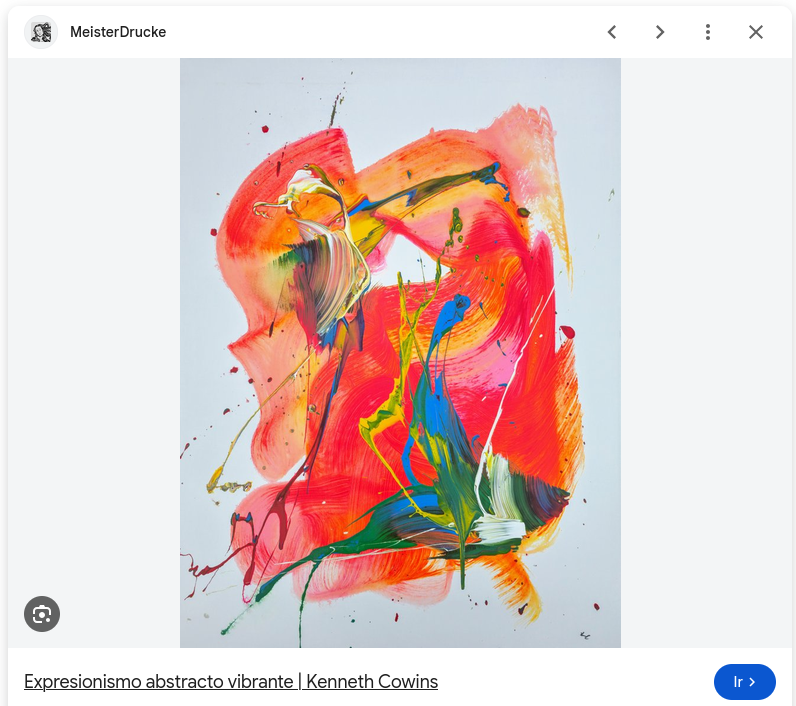

In [12]:
# best min|d chi|/g^2 for each probe position (both sign regions)
print(f"{'position':>12s}  {'chi_C<0':>10s}  {'chi_C>0':>10s}")
for s, lab in zip(scans, pos_labels):
    mn = np.nanmax(s['neg']['gap_grid']) if np.isfinite(s['neg']['gap_grid']).any() else np.nan
    mp = np.nanmax(s['pos']['gap_grid']) if np.isfinite(s['pos']['gap_grid']).any() else np.nan
    print(f"{lab:>12s}  {mn:10.3g}  {mp:10.3g}")

    position     chi_C<0     chi_C>0
   below all      0.0406      0.0355
     gap 0-1       0.941       0.499
     gap 1-2        3.33          15
     gap 2-3           2       0.853
     gap 3-4        8.54        2.63
     gap 4-5       0.803        1.67
   above all       0.553       0.183


### Smallest per-mode shift vs probe position

The same probe-position scan, but now the colour is $\min_i|\chi_i|/g^2$ (the
weakest imprint any single chain mode leaves on the probe) instead of the
closest-pair gap. Reuses the `chi_cube` that each `scans` entry already holds —
no new sweep. Where this is small, some mode is effectively invisible to the
probe even if the shifts are otherwise well spread.

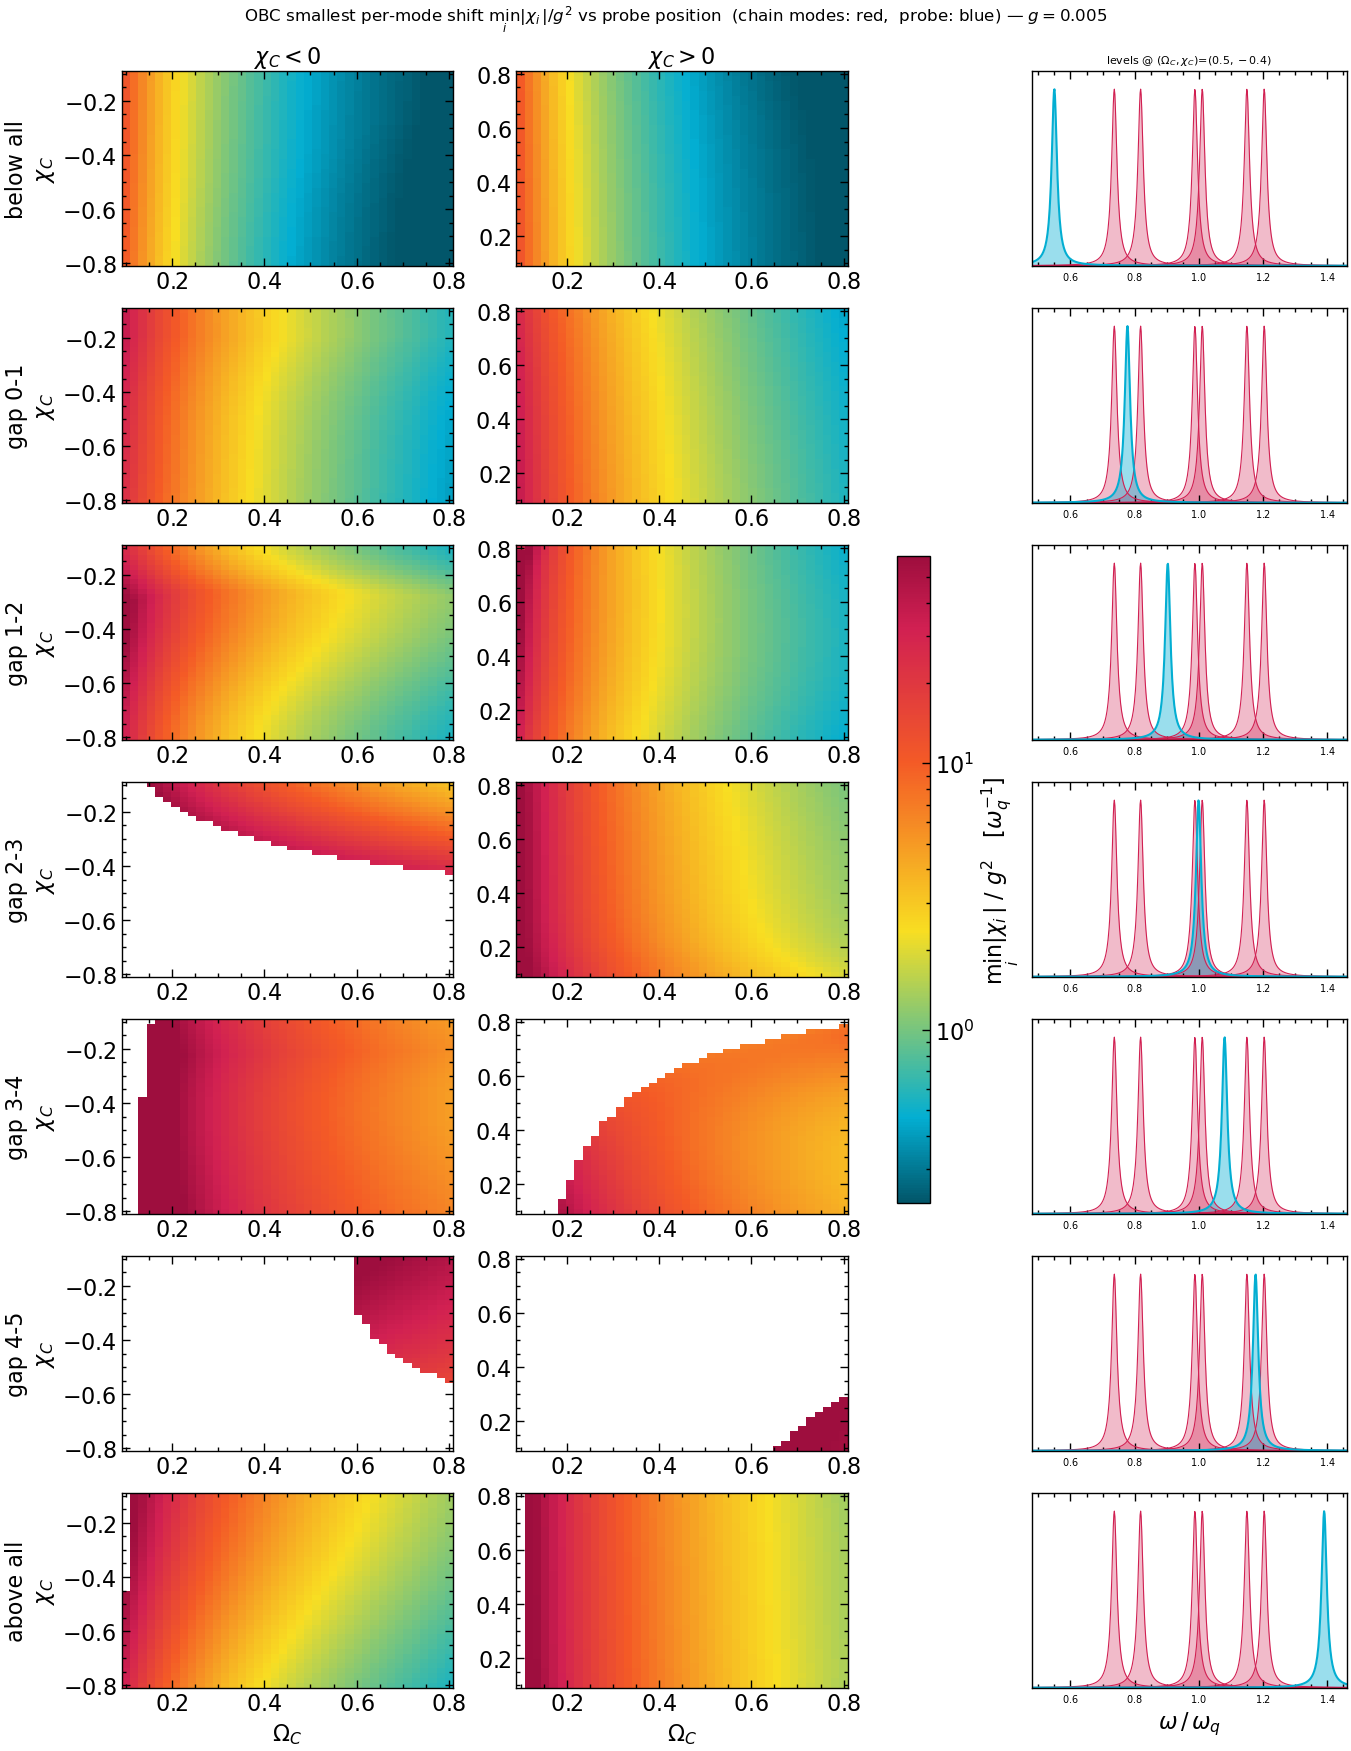

    position     chi_C<0     chi_C>0   (best min_i|chi_i|/g^2)
   below all        11.2        11.3
     gap 0-1        36.6        35.9
     gap 1-2        72.9        96.4
     gap 2-3        61.7        81.8
     gap 3-4         151        48.3
     gap 4-5        70.1        72.9
   above all        67.7        75.8


In [13]:
# min_i |chi_i| / g^2 vs probe position -- same layout as the discriminability
# scan above, straight out of each scan's chi_cube (all-NaN slice -> NaN).
minabs = [{sgn: np.min(np.abs(s[sgn]['chi_cube']), axis=-1) / g_big ** 2
           for sgn in ('neg', 'pos')} for s in scans]

allv = np.concatenate([M[sgn][np.isfinite(M[sgn]) & (M[sgn] > 0)]
                       for M in minabs for sgn in ('neg', 'pos')])
norm_ma = LogNorm(*np.percentile(allv, [2, 98]))

fig, axes = plt.subplots(nr, 3, figsize=(13.5, 2.5 * nr), squeeze=False,
                         gridspec_kw={'width_ratios': [1, 1, 0.95]},
                         constrained_layout=True)
last = None
for r, (M, lab, gi) in enumerate(zip(minabs, pos_labels, positions)):
    for c, (sgn, cv) in enumerate([('neg', chi_C_neg), ('pos', chi_C_pos)]):
        ax = axes[r, c]
        im = log_heatmap(ax, omega_C_values, cv, M[sgn], norm=norm_ma, contours=False)
        last = im or last
        if r == 0:
            ax.set_title((r'$\chi_C<0$', r'$\chi_C>0$')[c])
        if c == 0:
            ax.set_ylabel(f'{lab}\n' + r'$\chi_C$')
        if r == nr - 1:
            ax.set_xlabel(r'$\Omega_C$')

    axd = axes[r, 2]
    for wm in modes_ref:
        axd.fill_between(w_axis, lorentzian(wm), color=CHAIN_C, alpha=0.30, lw=0)
        axd.plot(w_axis, lorentzian(wm), color=CHAIN_C, lw=0.8)
    wp = ref.probe_freq_in_gap(gi)
    axd.fill_between(w_axis, lorentzian(wp), color=RES_C, alpha=0.40, lw=0)
    axd.plot(w_axis, lorentzian(wp), color=RES_C, lw=1.5)
    axd.set_xlim(w_axis[0], w_axis[-1]); axd.set_ylim(0, 1.1)
    axd.set_yticks([]); axd.tick_params(labelsize=7)
    if r == 0:
        axd.set_title(rf'levels @ $(\Omega_C,\chi_C)\!=\!({oc_ref},{cc_ref})$', fontsize=8)
    if r == nr - 1:
        axd.set_xlabel(r'$\omega\,/\,\omega_q$')

fig.colorbar(last, ax=list(axes[:, :2].ravel()), label=MINABS_LABEL, shrink=0.4)
fig.suptitle(rf'OBC smallest per-mode shift $\min_i|\chi_i|/g^2$ vs probe position  '
             rf'(chain modes: red,  probe: blue) — $g={g_big:g}$')
plt.show()

print(f"{'position':>12s}  {'chi_C<0':>10s}  {'chi_C>0':>10s}   (best min_i|chi_i|/g^2)")
for M, lab in zip(minabs, pos_labels):
    mn = np.nanmax(M['neg']) if np.isfinite(M['neg']).any() else np.nan
    mp = np.nanmax(M['pos']) if np.isfinite(M['pos']).any() else np.nan
    print(f"{lab:>12s}  {mn:10.3g}  {mp:10.3g}")

## Periodic boundary conditions

With `PBC=True` the chain is translation-invariant: the $\eta$ modes carry a
crystal momentum $k$ and the $\pm k$ pairs are **exactly degenerate in
frequency**. The probe cross-Kerr $V''\propto\beta_0^\dagger\beta_0\,
\beta_i^\dagger\beta_j$ conserves momentum, so its $\pm k$ block is diagonal and
the pair is degenerate **in $\chi$ too**. So at most $N+1$ shift values are ever
distinct and the discriminability metric is $\equiv 0$ everywhere.

In [ ]:
# OBC vs PBC at one representative gapped point
oc_rep, cc_rep = 0.6, -0.35
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for pbc, mk, lab in [(False, 'o', 'OBC'), (True, 's', 'PBC')]:
    ch = make_chain(oc_rep, cc_rep, pbc)
    oe = 2.0 * np.diag(ch.H_C)[:n].real
    wr = ch.probe_freq_in_gap(-1)
    chi = ch.compute_resonator_dispersive_shift_vec_from_sites(wr, g_sites, dispersive_tol=1.0)
    axes[0].plot(np.arange(n), oe, mk + '-', label=lab, ms=7)
    axes[1].plot(np.arange(n), np.sort(chi) / NORM, mk + '-', label=lab, ms=7)
    print(f"{lab}: min|d chi|/g^2 = {min_pairwise_gap(chi) / NORM:.3g} [1/w_q]")
axes[0].set_xlabel('mode index'); axes[0].set_ylabel(r'$\omega_\eta$')
axes[0].set_title(r'$\eta$-mode frequencies'); axes[0].legend()
axes[1].set_xlabel('rank'); axes[1].set_ylabel(r'$\chi\ /\ g^2\quad[\omega_q^{-1}]$')
axes[1].set_title(r'sorted dispersive shifts'); axes[1].legend()
fig.suptitle(r'PBC $\pm k$ pairs collapse in both $\omega_\eta$ and $\chi$')
plt.show()

### Can an alternating-sign probe split the $\pm k$ pairs?

**No.** $g_j\propto(-1)^j$ has period 2 = the SSH unit cell, so it is still
translation-invariant and lives at $k=0$ in Fourier space — it only reaches the
two $k=0$ Bloch modes ($g'_k=0$ for $k\neq0$). **A translation-symmetry-breaking
real profile** (gradient, localized bump, random) both reaches the $k\neq0$ modes
and hybridizes each $\pm k$ pair into standing waves with distinct $\chi$. (OBC is
the same mechanism, handed to you by the boundary.) You do not need to break
time-reversal.

In [ ]:
ch = make_chain(0.6, -0.35, pbc=True)
jj = np.arange(n)
wr = ch.probe_freq_in_gap(-1)
profiles = {
    'uniform  (1,1,...)'          : np.ones(n),
    'alternating  (1,-1,...)'     : (-1.0) ** jj,
    'gradient (transl. broken)'   : 1.0 + 0.6 * jj / n,
    'bump on site 0'              : np.exp(-(jj % n) ** 2 / 1.5) + 0.05,
}
print('eta freqs (PBC):', np.round(2.0 * np.diag(ch.H_C)[:n].real, 4))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, prof in profiles.items():
    gs  = g_const * prof / np.abs(prof).max()
    gpr = ch.compute_coupling_vec_from_sites(gs)
    chi = ch.compute_resonator_dispersive_shift_vec_from_sites(wr, gs, dispersive_tol=1.0)
    print(f"{name:28s}  g' on {int(np.sum(np.abs(gpr) > 1e-6 * g_const))} modes | "
          f"min|d chi|/g^2 = {min_pairwise_gap(chi) / NORM:9.3g} [1/w_q]")
    ax.plot(jj, chi / NORM, 'o-', label=name, ms=5)
ax.set_xlabel('mode index'); ax.set_ylabel(r'$\chi\ /\ g_{\rm const}^2\quad[\omega_q^{-1}]$')
ax.set_title('PBC dispersive shifts vs coupling profile'); ax.legend(fontsize=7)
plt.show()